# Practice work # 2

> Student name    - Rodion

> Student surname - Ostapenko

> Group           - CS-32

### Task

Реалізувати обчислення лінійної регресії точним методом та за допомогою методу градієнтного спуску.
Порівняти результати, що були  отримані двома методами. 
До Гугл-класу прикріпити Jupiter Notebook, де проведені вказані обчислення та текстові комірки для оформлення та пояснення дій і результатів.

In [20]:
import numpy as np
import matplotlib.pyplot as plt
SEED = 20

n_features = 1
n_samples = 100

#### Для початку сгенеруємо дані. Також сгенеруємо синтетичні дані з деяким шумом

In [67]:
def generate_linear_data(n_features, n_samples, noise=5):
    np.random.seed(SEED)
    true_bias = np.random.uniform(-10, 10)
    true_weights = np.random.uniform(-10, 10, size=n_features)
    
    X = np.random.rand(n_samples, n_features) * 10 - 5
    y = true_bias + (true_weights @ X.T)
    
    y_noised = y + np.random.normal(scale=noise, size=n_samples)
    
    return X, y_noised, [true_bias, true_weights]

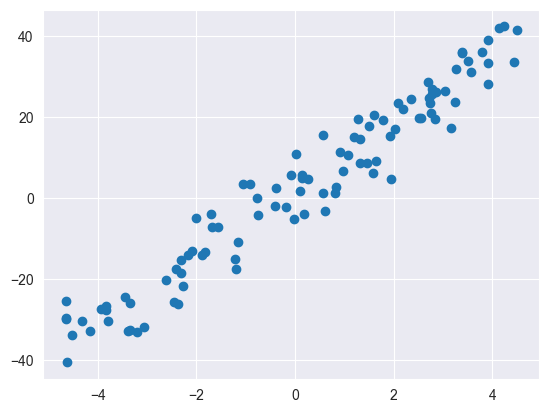

In [68]:
noise_data = generate_linear_data(n_features, n_samples)
noise_true_weights = noise_data[2]
plt.scatter(noise_data[0], noise_data[1])

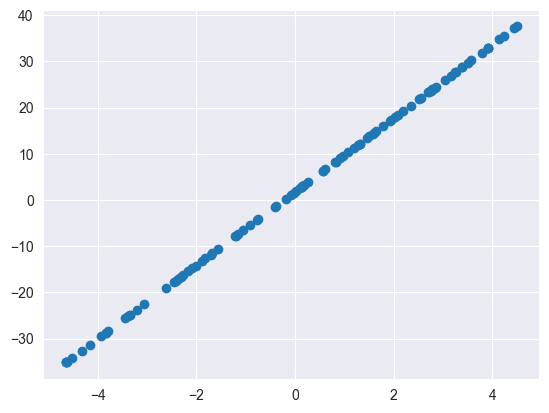

In [69]:
data = generate_linear_data(n_features, n_samples, noise=0)
true_weights = data[2]
plt.scatter(data[0], data[1])

In [261]:
def print_compare(calculated_weights, real_weights):
    bias = calculated_weights[0]
    weights = calculated_weights[1:]
    true_bias, true_weights = real_weights
    print(f"Обчислене відхилення: {bias:.8f}, Реальне відхилення: {true_bias:.8f} | Різниця: {abs(true_bias-bias):.8f}")
    for w, true_w in zip(weights, true_weights):
        print(f"Обчислені ваги: {w:.8f}, Реальні ваги: {true_w:.8f} | Різниця: {abs(w-true_w):.8f}")

## Реалізація точного методу
$$\widehat{\mathbf{\theta}} = (\mathbf{X}^{\top}\mathbf{X})^{-1}\mathbf{X}^{\top}\mathbf{y}$$

In [363]:
def closed_form_solution(X, y):
    X_with_bias = np.column_stack((np.ones(n_samples), X))
    weights = np.linalg.inv(X_with_bias.T @ X_with_bias) @ X_with_bias.T @ y
    return weights

In [364]:
results = closed_form_solution(data[0], data[1])
print_compare(results, true_weights)

Обчислене відхилення: 1.76261602, Реальне відхилення: 1.76261602 | Різниця: 0.00000000
Обчислені ваги: 7.95427456, Реальні ваги: 7.95427456 | Різниця: 0.00000000


In [267]:
results = closed_form_solution(noise_data[0], noise_data[1])
print_compare(results, true_weights)

Обчислене відхилення: 1.91438608, Реальне відхилення: 1.76261602 | Різниця: 0.15177006
Обчислені ваги: 8.15452169, Реальні ваги: 7.95427456 | Різниця: 0.20024713


## Реалізація градієнтного спуску
$$\text{MSE}(\mathbf{X}, h_{\boldsymbol{\theta}}) = \frac{1}{m} \sum_{i=1}^{m} \left( \boldsymbol{\theta}^{\top}\mathbf{x}^{(i)} - y^{(i)} \right)^2$$

$$\nabla_{\boldsymbol{\theta}} \text{MSE}(\boldsymbol{\theta}) = \frac{2}{m} \mathbf{X}^{\top}(\mathbf{X}\boldsymbol{\theta} - \mathbf{y})$$

In [312]:
def mse(y_true, X, theta):
    m = len(y_true)
    MSE = (1/m) * sum((X @ theta - y_true)** 2) 
    return MSE

def mse_gradient(y_true, X, theta):
    m = len(y_true)
    gradient = (2/m) * (X.T @ (X @ theta - y_true))
    return gradient

def batch_gradient_descent(X, y, epoches=100, learning_rate=0.1):
    X_with_bias = np.column_stack((np.ones(n_samples), X))
    current_weights = np.random.uniform(-1, 1, size=n_features+1)
    
    for i in range(epoches):
        MSE = mse(y, X_with_bias, current_weights)
        if i % 20 == 0:
            print(f"Epoch {i+1}: MSE {MSE:.8f} | Weights: {current_weights}")
        error = mse_gradient(y, X_with_bias, current_weights)
        current_weights -= learning_rate * error
    return current_weights

In [313]:
results = batch_gradient_descent(data[0], data[1])
print_compare(results, true_weights)

Epoch 1: MSE 504.89174780 | Weights: [-0.04752845 -0.50607551]
Epoch 21: MSE 0.00035221 | Weights: [1.7438205  7.95473648]
Epoch 41: MSE 0.00000005 | Weights: [1.7623954  7.95427998]
Epoch 61: MSE 0.00000000 | Weights: [1.76261343 7.95427462]
Epoch 81: MSE 0.00000000 | Weights: [1.76261599 7.95427456]
Обчислене відхилення: 1.76261602, Реальне відхилення: 1.76261602 | Різниця: 0.00000000
Обчислені ваги: 7.95427456, Реальні ваги: 7.95427456 | Різниця: 0.00000000


In [314]:
results = batch_gradient_descent(noise_data[0], noise_data[1])
print_compare(results, true_weights)

Epoch 1: MSE 578.78038817 | Weights: [-0.23724604 -0.67152043]
Epoch 21: MSE 27.55576177 | Weights: [1.89168998 8.15507948]
Epoch 41: MSE 27.55524827 | Weights: [1.91411967 8.15452824]
Epoch 61: MSE 27.55524820 | Weights: [1.91438295 8.15452177]
Epoch 81: MSE 27.55524820 | Weights: [1.91438604 8.15452169]
Обчислене відхилення: 1.91438608, Реальне відхилення: 1.76261602 | Різниця: 0.15177006
Обчислені ваги: 8.15452169, Реальні ваги: 7.95427456 | Різниця: 0.20024713


### Точний метод, як і градієнтний спуск показали чудові результати на обох датасетах. На датасеті з шумом розраховані ваги мають однакову різницю з реальними вагами для обох методів

### Збільшемо кількість фіч для порівняння обох методів в випадках коли ми маємо набагато більше колонок у матриці, аніж рядків

In [380]:
n_features = 8000
n_samples = 100

In [381]:
many_features_data = generate_linear_data(n_features, n_samples, noise=2)
X, y = many_features_data[0], many_features_data[1]
true_weights = many_features_data[2]

In [382]:
print(X.shape)
print(y.shape)

(100, 8000)
(100,)


In [383]:
import time
t1 = time.time()
results = closed_form_solution(X, y)
t2 = time.time()
print(f"Time: {t2-t1}")

Time: 11.163553237915039


In [384]:
print_compare(results[:9], true_weights[:9])

Обчислене відхилення: 7999485.33227972, Реальне відхилення: 1.76261602 | Різниця: 7999483.56966370
Обчислені ваги: 5078189.29708700, Реальні ваги: 7.95427456 | Різниця: 5078181.34281244
Обчислені ваги: -6959648.84157515, Реальні ваги: 7.83061459 | Різниця: 6959656.67218973
Обчислені ваги: -5878959.12843164, Реальні ваги: 6.31674955 | Різниця: 5878965.44518118
Обчислені ваги: 847146.99747059, Реальні ваги: -9.28220829 | Різниця: 847156.27967888
Обчислені ваги: -4179001.05517164, Реальні ваги: 3.83515164 | Різниця: 4179004.89032327
Обчислені ваги: 4173204.42070657, Реальні ваги: -2.42638116 | Різниця: 4173206.84708773
Обчислені ваги: -100886.07432904, Реальні ваги: 0.37021891 | Різниця: 100886.44454795
Обчислені ваги: 3248628.53565188, Реальні ваги: 3.15902931 | Різниця: 3248625.37662257


In [385]:
t1 = time.time()
results = batch_gradient_descent(X, y, epoches=100, learning_rate=0.001)
t2 = time.time()
print(f"Time: {t2-t1}")

Epoch 1: MSE 1732642.23411891 | Weights: [ 0.48906278  0.71351175 -0.81308345 ... -0.50767907 -0.57103168
  0.02017143]
Epoch 21: MSE 0.00044899 | Weights: [ 0.47033198  1.13791048 -1.26601632 ... -0.72103143 -0.98519253
 -0.03362711]
Epoch 41: MSE 0.00000000 | Weights: [ 0.47033166  1.13790959 -1.26602042 ... -0.72102518 -0.98519686
 -0.03362419]
Epoch 61: MSE 0.00000000 | Weights: [ 0.47033166  1.13790959 -1.26602042 ... -0.72102518 -0.98519686
 -0.03362419]
Epoch 81: MSE 0.00000000 | Weights: [ 0.47033166  1.13790959 -1.26602042 ... -0.72102518 -0.98519686
 -0.03362419]
Time: 0.047659873962402344


In [386]:
print_compare(results[:9], true_weights[:9])

Обчислене відхилення: 0.47033166, Реальне відхилення: 1.76261602 | Різниця: 1.29228436
Обчислені ваги: 1.13790959, Реальні ваги: 7.95427456 | Різниця: 6.81636497
Обчислені ваги: -1.26602042, Реальні ваги: 7.83061459 | Різниця: 9.09663501
Обчислені ваги: 0.33847614, Реальні ваги: 6.31674955 | Різниця: 5.97827340
Обчислені ваги: 0.11733526, Реальні ваги: -9.28220829 | Різниця: 9.39954355
Обчислені ваги: -1.01829726, Реальні ваги: 3.83515164 | Різниця: 4.85344890
Обчислені ваги: -0.97807903, Реальні ваги: -2.42638116 | Різниця: 1.44830213
Обчислені ваги: -1.05260012, Реальні ваги: 0.37021891 | Різниця: 1.42281903
Обчислені ваги: -0.54693452, Реальні ваги: 3.15902931 | Різниця: 3.70596383


### З такою кількістю синтетичних даних точному методу знадобилося 10 секунд обчислень, а також через деякі обмеження операції numpy.linalg.inv обчислені ваги дуже далекі від реальних.
### Для методу градієнтного спуску прийшлося зменшити learning rate до 0.001, щоб уникнути пропуску глобального мінімуму градієнтом. Після чого вже приблизно у 50 епосі помилка зменшилася до мінімальних значень. Цей метод також добре показав себе у використаному часі: 0.04 секунди. 